In [10]:
import pandas as pd
df[df["treatment"] == "Drug A"]

,patient_id,site,sex,age,treatment,biomarker_value,adverse_event,completion_status
0,1001,Site A,Male,34,Drug A,12.4,Yes,Completed
1,1002,Site A,M,41,Drug A,11.8,No,completed
6,1007,Site A,Female,63,Drug A,18.7,Yes,Completed
8,1009,Site C,male,31,Drug A,13.3,No,Completed
11,1012,Site B,M,49,Drug A,14.1,Yes,Withdrawn
14,1015,Site B,M,58,Drug A,17.9,Yes,Completed
17,1018,Site B,F,39,Drug A,12.9,No,Completed


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         20 non-null     int64  
 1   site               20 non-null     object 
 2   sex                20 non-null     object 
 3   age                20 non-null     int64  
 4   treatment          20 non-null     object 
 5   biomarker_value    16 non-null     float64
 6   adverse_event      20 non-null     object 
 7   completion_status  20 non-null     object 
dtypes: float64(1), int64(2), object(5)
memory usage: 1.4+ KB


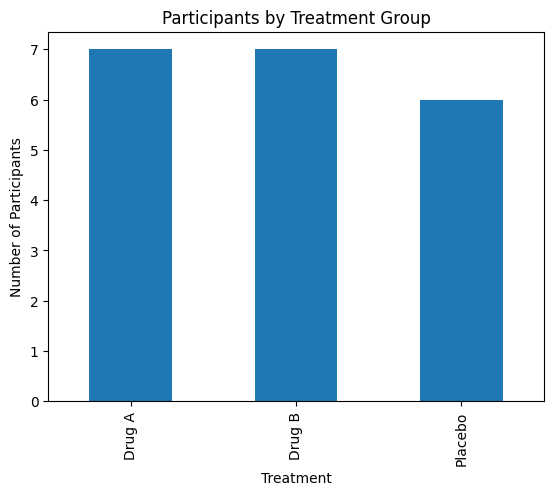

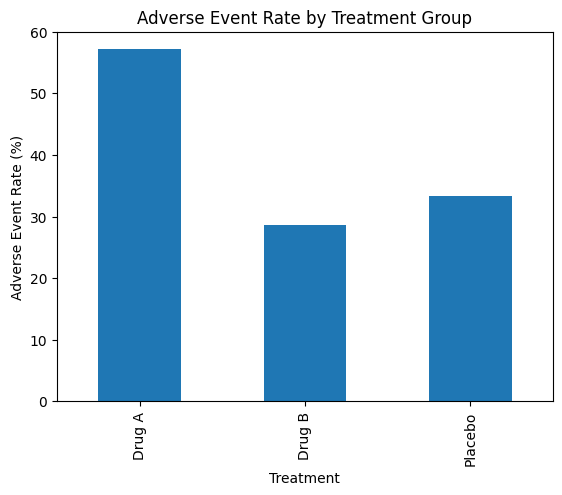

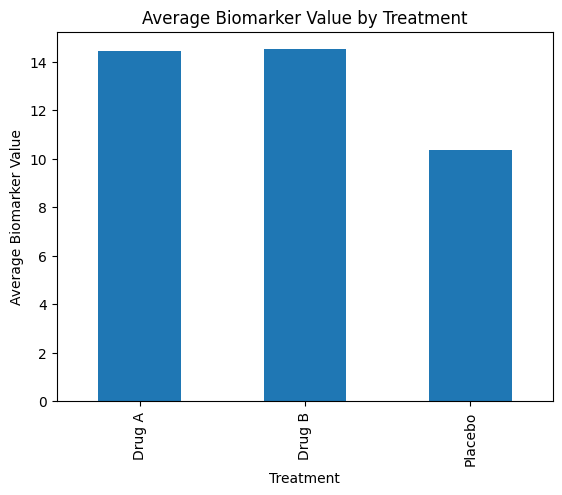

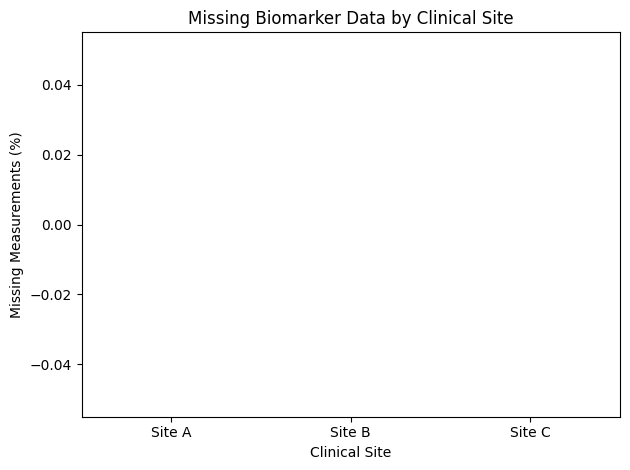

In [54]:
data = {
    "patient_id": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010,
                   1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020],

    "site": ["Site A", "Site A", "Site B", "Site B", "Site C",
             "Site C", "Site A", "Site B", "Site C", "Site A",
             "Site C", "Site B", "Site A", "Site C", "Site B",
             "Site A", "Site C", "Site B", "Site A", "Site C"],

    "sex": ["Male", "M", "female", "F", "Male",
            "M", "Female", "F", "male", "F",
            "Female", "M", "male", "Female", "M",
            "female", "Male", "F", "M", "Female"],

    "age": [34, 41, 29, 52, 47, 38, 63, 45, 31, 27,
            56, 49, 36, 42, 58, 33, 61, 39, 44, 50],

    "treatment": ["Drug A", "Drug A", "Drug B", "Drug B", "Placebo",
                  "placebo", "Drug A", "Drug B", "Drug A", "Drug B",
                  "Placebo", "Drug A", "Drug B", "placebo", "Drug A",
                  "Drug B", "Placebo", "Drug A", "Drug B", "Placebo"],

    "biomarker_value": [12.4, 11.8, 15.2, None, 10.1,
                        9.8, 18.7, None, 13.3, 16.5,
                        8.9, 14.1, None, 10.7, 17.9,
                        15.8, None, 12.9, 14.8, 9.5],

    "adverse_event": ["Yes", "No", "No", "Yes", "No",
                      "No", "Yes", "No", "No", "Yes",
                      "No", "Yes", "No", "No", "Yes",
                      "No", "Yes", "No", "No", "Yes"],

    "completion_status": ["Completed", "completed", "Complete", "Completed",
                          "Completed", "completed", "Completed", "Withdrawn",
                          "Completed", "complete", "Completed", "Withdrawn",
                          "Completed", "Completed", "Completed", "Completed",
                          "Withdrawn", "Completed", "Completed", "complete"]
}

df = pd.DataFrame(data)
df.head()
df.shape
df.info()
df["sex"].unique()
df["sex"] = df["sex"].replace({
    "M": "Male",
    "male": "Male",
    "F": "Female",
    "female": "Female"
})
df["treatment"].unique()
df["treatment"] = df["treatment"].str.title()
df["completion_status"].unique()
df["completion_status"] = df["completion_status"].replace({
    "completed": "Completed",
    "Complete": "Completed",
    "complete": "Completed"
})
df["completion_status"].unique()
df.isnull().sum()
missing_percentage = df.isnull().mean() * 100

median_biomarker = df["biomarker_value"].median()

df["biomarker_value"] = df["biomarker_value"].fillna(median_biomarker)
df.isnull().sum()
df["treatment"].value_counts()
drug_a = df.query("treatment == 'Drug A'")

drug_a
df.query("treatment == 'Drug A' and age > 40 and adverse_event == 'Yes'")
adverse_events = pd.crosstab(
    df["treatment"],
    df["adverse_event"]
)

adverse_events
adverse_event_rate = (
    df.groupby("treatment")["adverse_event"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

adverse_event_rate
completion = pd.crosstab(
    df["treatment"],
    df["completion_status"]
)

completion
df["site"].value_counts()
df.groupby("site")["biomarker_value"].mean()
df["biomarker_missing"] = df["biomarker_value"].isnull()
import matplotlib.pyplot as plt
df["treatment"].value_counts().plot(kind="bar")

plt.title("Participants by Treatment Group")
plt.xlabel("Treatment")
plt.ylabel("Number of Participants")

plt.show()
adverse_event_rate.plot(kind="bar")

plt.title("Adverse Event Rate by Treatment Group")
plt.xlabel("Treatment")
plt.ylabel("Adverse Event Rate (%)")

plt.show()
df.groupby("treatment")["biomarker_value"].mean().plot(kind="bar")

plt.title("Average Biomarker Value by Treatment")
plt.xlabel("Treatment")
plt.ylabel("Average Biomarker Value")

plt.show()
df.groupby("treatment")["biomarker_value"].mean().plot(kind="bar")

plt.title("Average Biomarker Value by Treatment")
plt.xlabel("Treatment")
plt.ylabel("Average Biomarker Value")

plt.show()
# Key Findings

## Data Quality

The original dataset contained inconsistent categorical values across sex, treatment, and completion-status fields. These values were standardized to improve consistency and support downstream analysis.

## Missing Data

Several biomarker measurements were miss

        participants  missing_biomarkers  missing_rate_percent
site                                                          
Site A             7                   1             14.285714
Site B             6                   2             33.333333
Site C             7                   1             14.285714


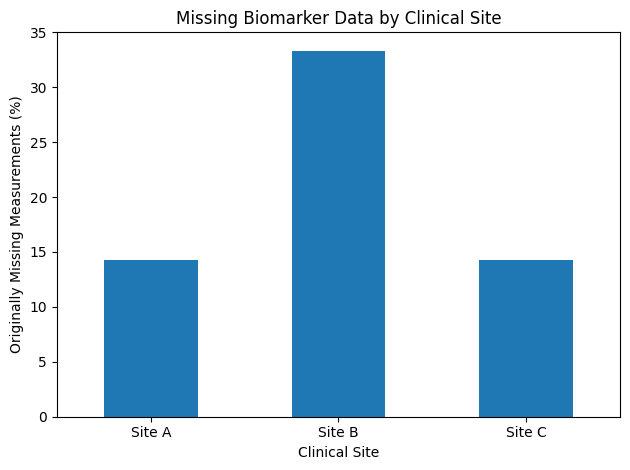

In [57]:
# Recover which biomarker values were originally missing
df["biomarker_missing"] = df["patient_id"].isin([1004, 1008, 1013, 1017])

# Recalculate missing biomarker data by site
site_quality = df.groupby("site").agg(
    participants=("patient_id", "count"),
    missing_biomarkers=("biomarker_missing", "sum")
)

site_quality["missing_rate_percent"] = (
    site_quality["missing_biomarkers"]
    / site_quality["participants"] * 100
)

# Display the results
print(site_quality)
import matplotlib.pyplot as plt

site_quality["missing_rate_percent"].plot(kind="bar")

plt.title("Missing Biomarker Data by Clinical Site")
plt.xlabel("Clinical Site")
plt.ylabel("Originally Missing Measurements (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Clinical Trials Data Cleaning and Analysis

## Project objective

The goal of this project is to clean, standardize, and analyze clinical-trial data collected from multiple research sites.

The analysis will focus on:

-Data quality and consistency
-Missing laboratory values
-Treatment groups
-Adverse events
-Trial completion status
-Differences between clinicak sites

**Dataset:** Synthetic clinical0trial data
**Tools:** Python, Pandas, Matplotlib


# Key Findings

## Data Quality

The original dataset contained inconsistent categorical values across sex, treatment, and completion-status fields. These values were standardized to improve consistency and support downstream analysis.

## Missing Data

Several biomarker measurements were missing. Missingness was identified using Pandas and the values were handled using median imputation for this demonstration.

## Treatment Groups

Participants were distributed across Drug A, Drug B, and Placebo groups.

## Adverse Events

Adverse-event rates were calculated for each treatment group to demonstrate how clinical safety data can be summarized using Python.

## Trial Completion

Completion and withdrawal status were compared across treatment groups.

## Limitations

This dataset is synthetic and intentionally simplified for educational purposes. The analysis should not be interpreted as clinical evidence or used to make medical conclusions. In a real clinical-trial dataset, missing-data mechanisms, protocol definitions, statistical methods, and regulatory requirements would need to be carefully evaluated.

## Conclusion

This project demonstrates how Python can be used to clean, organize, and analyze clinical trial data. I standardized inconsistent categories, identified missing biomarker measurements, and summarized treatment-group adverse events, participant completion, and data quality across clinical sites. I also created visualizations to make the results easier to understand. This project helped me develop practical skills in data cleaning, exploratory data analysis, and data visualization using pandas and Matplotlib. The dataset is synthetic and is intended for educational purposes only.